In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset path
root = Path(r"D:\AMME5710_Major_Project\dataset")
split = "val"

# 2. Output folder
output_dir = root.parent / "results" / "rgb_difference"
output_dir.mkdir(parents=True, exist_ok=True)

# 3. Find all images in validation set
files = sorted((root / split / "B").glob("*.png"))

if not files:
    raise FileNotFoundError("No PNG files found. Check dataset path.")

# 4. Count samples by category
categories = [
    path.name.split("_")[0] for path in files
]

category_counts = Counter(categories)

print("Total images:", len(files))
print("\nImages per category:")

for category, count in sorted(category_counts.items()):
    print(f"{category}: {count}")

print("\nResults will be saved to:", output_dir)


Total images: 523

Images per category:
blackspot: 158
colorshift: 163
friction: 39
hair: 105
line: 17
pinhole: 41

Results will be saved to: D:\AMME5710_Major_Project\results\rgb_difference


In [4]:
# Thresholds to evaluate
thresholds = list(range(5, 151, 5))

# Store TP, FP, FN for every threshold
overall_counts = np.zeros(
    (len(thresholds), 3), dtype=np.int64
)

# Store TP, FP, FN separately for each category
category_stats = defaultdict(
    lambda: np.zeros((len(thresholds), 3), dtype=np.int64)
)

processed = Counter()

for image_index, b_path in enumerate(files):

    filename = b_path.name
    category = filename.split("_")[0]

    # Read corresponding A, B and Ground Truth
    A = cv2.imread(
    str(root / split / "A" / filename),
    cv2.IMREAD_COLOR
    )

    B = cv2.imread(
    str(b_path),
    cv2.IMREAD_COLOR
    )

    GT = cv2.imread(
        str(root / split / "OUT" / filename),
        cv2.IMREAD_GRAYSCALE
     )

    if A is None or B is None or GT is None:
        raise FileNotFoundError(
            f"Missing image or ground truth: {filename}"
        )

    if A.shape != B.shape or A.shape[:2] != GT.shape:
        raise ValueError(
            f"Image size mismatch: {filename}"
        )

    # Absolute Difference
    colour_diff = cv2.absdiff(A, B)
    diff = np.max(colour_diff, axis=2)

    # Ground Truth Mask
    gt_mask = GT > 0

    # Test every threshold
    for i, t in enumerate(thresholds):

        # Equivalent to binary thresholding
        pred_mask = diff > t

        # Pixel-level evaluation
        TP = np.count_nonzero(pred_mask & gt_mask)
        FP = np.count_nonzero(pred_mask & ~gt_mask)
        FN = np.count_nonzero(~pred_mask & gt_mask)

        # Accumulate overall results
        overall_counts[i] += [TP, FP, FN]

        # Accumulate category-specific results
        category_stats[category][i] += [TP, FP, FN]

    processed[category] += 1

    if (image_index + 1) % 100 == 0:
        print(f"Processed {image_index + 1}/{len(files)} images")

print("\nBatch evaluation completed!")
print("Total processed:", sum(processed.values()))


Processed 100/523 images
Processed 200/523 images
Processed 300/523 images
Processed 400/523 images
Processed 500/523 images

Batch evaluation completed!
Total processed: 523


In [5]:
# Function for calculating evaluation metrics
def calculate_metrics(counts):

    TP, FP, FN = map(int, counts)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * TP / (2 * TP + FP + FN)
        if 2 * TP + FP + FN > 0 else 0
    )

    iou = (
        TP / (TP + FP + FN)
        if TP + FP + FN > 0 else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    }


# Overall results for every threshold
overall_results = []

for i, t in enumerate(thresholds):

    metrics = calculate_metrics(overall_counts[i])

    # Mean category F1, for additional comparison
    macro_f1 = np.mean([
        calculate_metrics(stats[i])["F1"]
        for stats in category_stats.values()
    ])

    overall_results.append({
        "Threshold": t,
        **metrics,
        "Macro_F1": float(macro_f1)
    })


# Select threshold with highest overall F1
best_index = int(np.argmax([
    row["F1"] for row in overall_results
]))

best_result = overall_results[best_index]
best_T = best_result["Threshold"]

print("Best validation threshold:", best_T)
print(f"Overall Precision: {best_result['Precision']:.4f}")
print(f"Overall Recall:    {best_result['Recall']:.4f}")
print(f"Overall F1:        {best_result['F1']:.4f}")
print(f"Overall IoU:       {best_result['IoU']:.4f}")
print(f"Macro category F1: {best_result['Macro_F1']:.4f}")


# Results by defect category at the same best T
category_results = []

print("\nPer-category performance:")
print(f"{'Category':15s} {'Images':>7s} {'F1':>8s} {'IoU':>8s}")

for category in sorted(category_stats):

    metrics = calculate_metrics(
        category_stats[category][best_index]
    )

    category_results.append({
        "Category": category,
        "Images": processed[category],
        **metrics
    })

    print(
        f"{category:15s} "
        f"{processed[category]:7d} "
        f"{metrics['F1']:8.4f} "
        f"{metrics['IoU']:8.4f}"
    )


# Save CSV files
for name, rows in [
    ("threshold_results.csv", overall_results),
    ("category_results.csv", category_results)
]:
    with open(
        output_dir / name,
        "w",
        newline="",
        encoding="utf-8"
    ) as f:

        writer = csv.DictWriter(
            f, fieldnames=list(rows[0].keys())
        )

        writer.writeheader()
        writer.writerows(rows)

print("\nCSV results saved.")


Best validation threshold: 40
Overall Precision: 0.7450
Overall Recall:    0.7052
Overall F1:        0.7245
Overall IoU:       0.5681
Macro category F1: 0.5084

Per-category performance:
Category         Images       F1      IoU
blackspot           158   0.5416   0.3714
colorshift          163   0.7641   0.6182
friction             39   0.4647   0.3027
hair                105   0.4990   0.3324
line                 17   0.2004   0.1114
pinhole              41   0.5805   0.4089

CSV results saved.


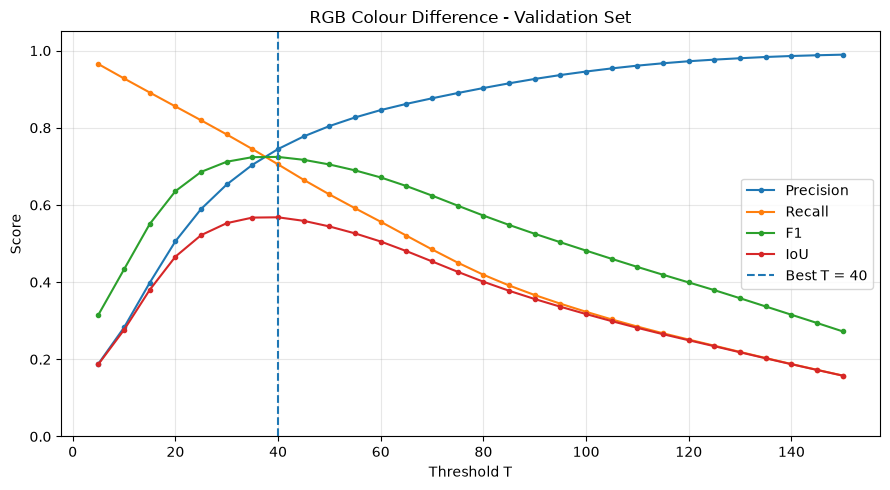

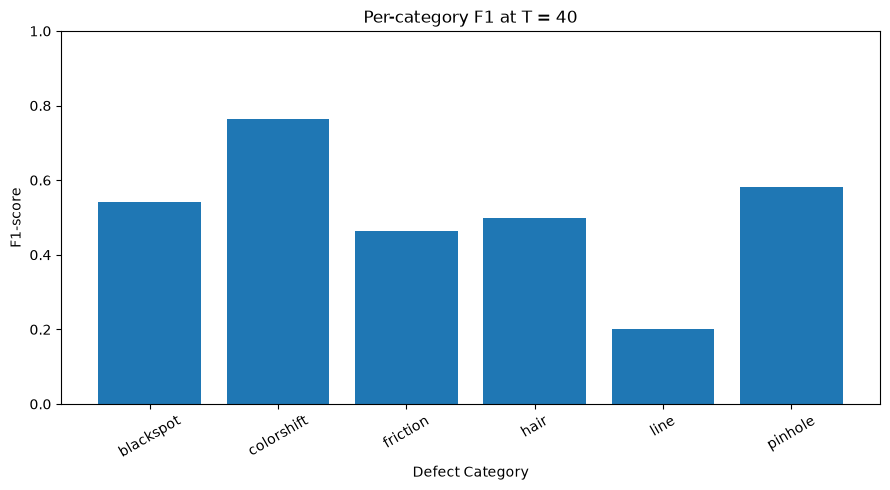

In [8]:
# Figure 1: Threshold analysis
plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1", "IoU"]:
    values = [row[metric] for row in overall_results]

    plt.plot(
        thresholds,
        values,
        marker=".",
        label=metric
        
    )

plt.axvline(
    best_T,
    linestyle="--",
    label=f"Best T = {best_T}"
)

plt.xlabel("Threshold T")
plt.ylabel("Score")
plt.title("RGB Colour Difference - Validation Set")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "threshold_analysis.png",
    dpi=300
)
plt.show()


# Figure 2: F1 by defect category
names = [row["Category"] for row in category_results]
scores = [row["F1"] for row in category_results]

plt.figure(figsize=(9, 5))
plt.bar(names, scores)

plt.xlabel("Defect Category")
plt.ylabel("F1-score")
plt.title(f"Per-category F1 at T = {best_T}")
plt.ylim(0, 1.0)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    output_dir / "category_f1.png",
    dpi=300
)
plt.show()


Overall Validation Comparison:
   Method  Best T  Precision  Recall     F1    IoU  Macro F1
Grayscale      20     0.6145  0.6288 0.6215 0.4509    0.4077
      RGB      40     0.7450  0.7052 0.7245 0.5681    0.5084

Per-category Comparison:
  Category  F1_Gray  F1_RGB  Improvement
 blackspot   0.3472  0.5416       0.1945
colorshift   0.6797  0.7641       0.0843
  friction   0.4933  0.4647      -0.0286
      hair   0.4174  0.4990       0.0816
      line   0.0609  0.2004       0.1396
   pinhole   0.4476  0.5805       0.1329


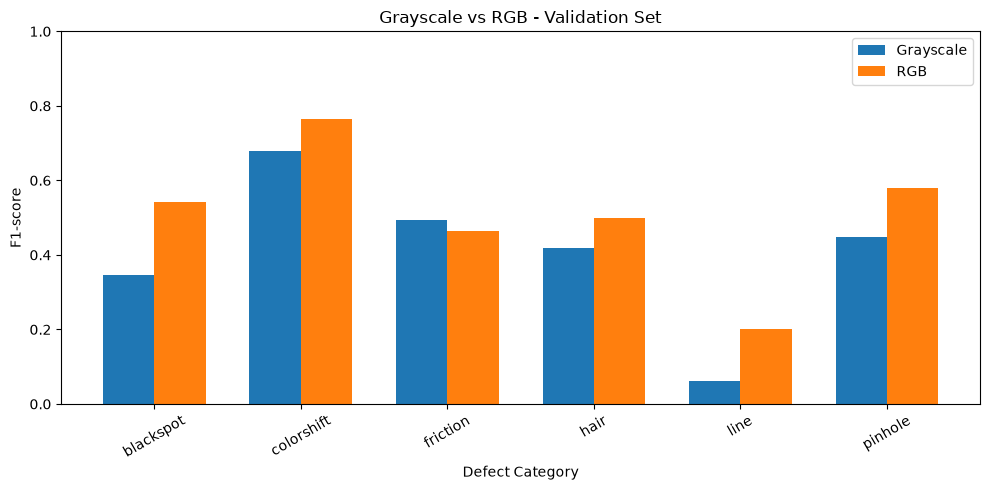

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Results folders
gray_dir = root.parent / "results" / "absolute_difference"
rgb_dir = root.parent / "results" / "rgb_difference"

# Read overall threshold results
gray = pd.read_csv(gray_dir / "threshold_results.csv")
rgb = pd.read_csv(rgb_dir / "threshold_results.csv")

# Find the best threshold for each method
gray_best = gray.loc[gray["F1"].idxmax()]
rgb_best = rgb.loc[rgb["F1"].idxmax()]

# Overall comparison
comparison = pd.DataFrame({
    "Method": ["Grayscale", "RGB"],
    "Best T": [
        int(gray_best["Threshold"]),
        int(rgb_best["Threshold"])
    ],
    "Precision": [
        gray_best["Precision"],
        rgb_best["Precision"]
    ],
    "Recall": [
        gray_best["Recall"],
        rgb_best["Recall"]
    ],
    "F1": [
        gray_best["F1"],
        rgb_best["F1"]
    ],
    "IoU": [
        gray_best["IoU"],
        rgb_best["IoU"]
    ],
    "Macro F1": [
        gray_best["Macro_F1"],
        rgb_best["Macro_F1"]
    ]
})

print("Overall Validation Comparison:")
print(comparison.round(4).to_string(index=False))

# Read per-category results
gray_cat = pd.read_csv(gray_dir / "category_results.csv")
rgb_cat = pd.read_csv(rgb_dir / "category_results.csv")

category_comparison = pd.merge(
    gray_cat[["Category", "F1"]],
    rgb_cat[["Category", "F1"]],
    on="Category",
    suffixes=("_Gray", "_RGB")
)

category_comparison["Improvement"] = (
    category_comparison["F1_RGB"]
    - category_comparison["F1_Gray"]
)

print("\nPer-category Comparison:")
print(category_comparison.round(4).to_string(index=False))

# Plot per-category comparison
x = np.arange(len(category_comparison))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    category_comparison["F1_Gray"],
    width,
    label="Grayscale"
)

plt.bar(
    x + width / 2,
    category_comparison["F1_RGB"],
    width,
    label="RGB"
)

plt.xticks(
    x,
    category_comparison["Category"],
    rotation=30
)

plt.ylabel("F1-score")
plt.xlabel("Defect Category")
plt.title("Grayscale vs RGB - Validation Set")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    rgb_dir / "gray_vs_rgb_comparison.png",
    dpi=300
)

plt.show()

# Save comparison tables
comparison.to_csv(
    rgb_dir / "overall_comparison.csv",
    index=False
)

category_comparison.to_csv(
    rgb_dir / "category_comparison.csv",
    index=False
)
